## Customer Churn Analysis — Exploratory Data Analysis

### Project Objective
- To explore customer data, identify patterns associated with customer churn, and generate meaningful business insights.


##### Meaning of each column from the dataset.

##### ********** 1. Personal details of the customer ********
- customerID = Unique identification number assigned to each customer.	Customer ID
- gender = Gender of the customer.	Male, Female
- SeniorCitizen	= Whether the customer is a senior citizen.	0 = No, 1 = Yes
- Partner = Whether the customer has a partner.	Yes, No
- Dependents = Whether the customer has dependents.	Yes, No

##### ******* 2. Account details of the Customer ********
- tenure = Number of months the customer has stayed with the company.	--> Numeric
- Contract = Type of contract selected by the customer.	Month-to-month, --> One year, Two year
- PaperlessBilling = Whether the customer receives bills electronically. --> Yes, No
- PaymentMethod	= Method used by the customer to pay bills. --> Electronic check, Mailed check, Bank transfer, Credit card


##### ******** 3. Services used by the Customer *******
- PhoneService = Whether the customer has telephone service -->	Yes, No
- MultipleLines = Whether the customer has multiple telephone lines. --> Yes, No, No phone service
- InternetService =	Type of internet connection used. --> DSL, Fiber optic, No
- OnlineSecurity = Whether the customer has online security service. --> Yes, No, No internet service
- OnlineBackup = Whether the customer has online backup service. --> Yes, No, No internet service
- DeviceProtection = Whether the customer has device protection. --> Yes, No, No internet service
- TechSupport = Whether the customer has technical support service.	--> Yes, No, No internet service
- StreamingTV = Whether the customer uses streaming TV services. --> Yes, No, No internet service
- StreamingMovies	Whether the customer uses streaming movie services.	--> Yes, No, No internet service


##### ******** 4. Financial Information ********
- MonthlyCharges = Amount charged to the customer every month. --> Numeric
- TotalCharges = Total amount charged to the customer throughout their association with the company.-->Numeric (stored as text in the original CSV)    TotalCharges = tenure * MonthlyCharges

##### ** Churn --> target column **
- Churn	Indicates whether the customer has left the company.	Yes, No
- - Yes means the customer has discontinued the company's services.
- - No means the customer has remained with the company


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statistics as stats
print("All Libraries imported Successfully..\nOur EDA environment is ready..")

All Libraries imported Successfully..
Our EDA environment is ready..


In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset loaded Successfull...")

Dataset loaded Successfull...


In [3]:
# Checking Sample of the dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Checking sample from the bottom of the dataset
df.tail() 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
print(f"Shape of the dataset: rows = {df.shape[0]}, columns = {df.shape[1]}")


Shape of the dataset: rows = 7043, columns = 21


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
df.info()
# TotalCharges has datatype as object instead it is a numerical column. But the dataset contains some blank space for this column in some rows.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
# Checking null values.
df.isnull().sum()
# Every column has some values. But those value can be duplicate, it can be unusual value.


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# We have to make  separate check for the TotalCharges because it has datatype as  object (string) and blank spaces.
# Pandas do not include blank spaces in null values.
df['TotalCharges'].value_counts().head()

TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
Name: count, dtype: int64

In [10]:
# We are checking this separately because blank strings are not treated as null values by Pandas.
print(f"Total number of blank spaces in TotalCharges column: {df['TotalCharges'].str.strip().eq('').sum()}")

Total number of blank spaces in TotalCharges column: 11


In [11]:
# Now verify why this 11 entries for the TotalCharges column are empty.
# Before cleaning the data we have to know why it is empty.
blank_record = df[df["TotalCharges"] == " "]
blank_record
# I verified  that the tenure of the customer is 0. That is why the TotalCharges are empty. We can replace it by 0.

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [12]:
blank_record[["customerID","tenure","MonthlyCharges","TotalCharges","Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


##### Replace the blank values  of TotalCharges with zero.
- Why ?
- These are valid customer records, not necessarily incorrect records.
- Their tenure is zero, which explains why they have no accumulated charges.
- Removing them would unnecessarily discard valid customer information.
- Replacing them with zero preserves all 7,043 customers


In [13]:
df["TotalCharges"] = df["TotalCharges"].str.strip()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors = 'coerce')
df["TotalCharges"] = df["TotalCharges"].fillna(0)


In [14]:
# Verification after changes
print(f"New data type of TotalCharges is {df['TotalCharges'].dtype}, Not null value is {df['TotalCharges'].isnull().sum()}")


New data type of TotalCharges is float64, Not null value is 0


In [15]:
# TotalCharges for tenure 0 has filled with 0.0
verify_df = df[df["tenure"]==0]
verify_df[["tenure","TotalCharges"]]

,tenure,TotalCharges
488,0,0.0
753,0,0.0
936,0,0.0
1082,0,0.0
1340,0,0.0
3331,0,0.0
3826,0,0.0
4380,0,0.0
5218,0,0.0
6670,0,0.0


#### Duplicate check

In [16]:
print("Number of duplicate rows in dataset ",int(df.duplicated().sum()))

Number of duplicate rows in dataset  0


In [17]:
print("Number of duplicate customer ID in the dataset ",int(df["customerID"].duplicated().sum()))

Number of duplicate customer ID in the dataset  0


- Duplicate rows: No completely duplicated records exist.
- Duplicate customer IDs: No customer ID is repeated.

### Statistical Summary of Numerical column

In [18]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


##### Key observation
- Approximately 16.2% of customers are senior citizens.
- Average customer has stayed for approximately 32 months.
- For MonthlyCharges notice that the mean is lower than the median. This suggests that some customers with relatively low monthly charges may be pulling the average downward. --> left skew or negative skewness.
- Third percentile (75%) represents that 75% customer have tenure upto 55 months with the company.
- 50% of customer have tenure upto 29 months
- 25% of customer have tenure upto 9 months

- Tenure has a standard deviation of approximately 24.56 months.
- MonthlyCharges has a standard deviation of approximately $30.09.
- Higher Standard deviation represent the greater variation in the dataset.

#### Categorical column Analysis

In [19]:
df["Churn"].value_counts()
# Outof 7043 customers 1869 leave the company.


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [20]:
df["Churn"].value_counts(normalize=True)*100 

# Churn rate is 26.53 %
# Retension rate is 73.46%

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

- Approximately 26.54% of customers have churned, while 73.46% have remained with the company. This indicates that around one in every four customers has left

In [21]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [22]:
df["Contract"].value_counts(normalize=True)*100

Contract
Month-to-month    55.019168
Two year          24.066449
One year          20.914383
Name: proportion, dtype: float64

- More than half of the customers (55.02%) have month-to-month contracts.
- Two-year contracts account for 24.07%.
- One-year contracts account for 20.91%.
- Most customers prefer month-to-month contracts rather than long-term commitments.

In [23]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [24]:
df["PaymentMethod"].value_counts(normalize=True)*100

PaymentMethod
Electronic check             33.579441
Mailed check                 22.887974
Bank transfer (automatic)    21.922476
Credit card (automatic)      21.610109
Name: proportion, dtype: float64

- Electronic check is the most commonly used  Payment Method.
- Credit card is the least commonly used  payment method.
- The other three payment methods have relatively similar proportions.

In [25]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [26]:
df["InternetService"].value_counts(normalize=True)*100

InternetService
Fiber optic    43.958540
DSL            34.374556
No             21.666903
Name: proportion, dtype: float64

- Fiber optic is most common internetService used by approx 44% of the customer.
- Approximately 21.67% of customers do not have internet service.

In [27]:
# We can analyse every categorical column simultaneously instead of doing one by one.
categorical_col = df.select_dtypes(include=object).columns.drop("customerID")
len(categorical_col)
categorical_col

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')

In [28]:
# Frequency distribution for categorical column
for col in categorical_col:
    
    print(df[col].value_counts())
    print("*"*40," ")

gender
Male      3555
Female    3488
Name: count, dtype: int64
****************************************  
Partner
No     3641
Yes    3402
Name: count, dtype: int64
****************************************  
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
****************************************  
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
****************************************  
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
****************************************  
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
****************************************  
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
****************************************  
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dt

In [29]:
# Percentage distribution for categorical column
for col in categorical_col:
    print(df[col].value_counts(normalize=True)*100)
    print("*"*40," ")


gender
Male      50.47565
Female    49.52435
Name: proportion, dtype: float64
****************************************  
Partner
No     51.69672
Yes    48.30328
Name: proportion, dtype: float64
****************************************  
Dependents
No     70.041176
Yes    29.958824
Name: proportion, dtype: float64
****************************************  
PhoneService
Yes    90.316626
No      9.683374
Name: proportion, dtype: float64
****************************************  
MultipleLines
No                  48.132898
Yes                 42.183729
No phone service     9.683374
Name: proportion, dtype: float64
****************************************  
InternetService
Fiber optic    43.958540
DSL            34.374556
No             21.666903
Name: proportion, dtype: float64
****************************************  
OnlineSecurity
No                     49.666335
Yes                    28.666761
No internet service    21.666903
Name: proportion, dtype: float64
*************************

##### Demographic column
- Male and female customers are almost equally distributed.
- Customers without partners slightly outnumber those with partners.
- Approximately 70% of customers do not have dependents.

##### Service related column 
- A significant proportion of customers do not subscribe to additional services such as OnlineSecurity, OnlineBackup and TechSupport.
- Almost similar proportion of customer subscribe  StreamingMovie and StreamingTV services. 

##### Account related column
- More people prefer paperless billing than traditional billing.
- Electronic check is the most commonly used payment method

##### Univariate Analysis

Text(0, 0.5, 'Number of customers')

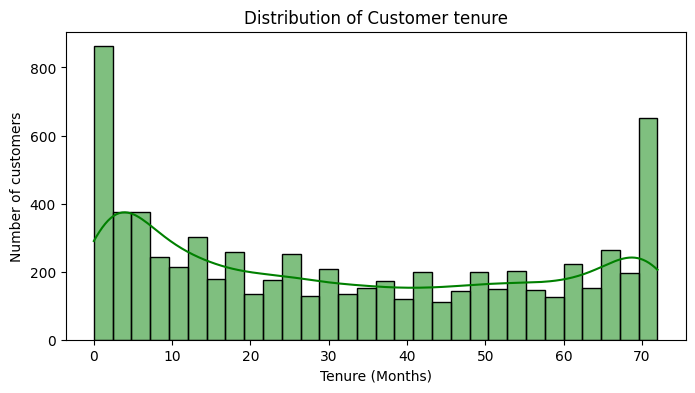

In [30]:
plt.figure(figsize=(8,4))
sns.histplot(data = df, x = "tenure", bins=30, kde = True , color="green")

plt.title("Distribution of Customer tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of customers")

- Higher bar nearly zero tenure indicates that many customer has recently joined the company.
- Almost 600 or above customer have stayed with the company for the long time.
- Customer tenure distribution shows two prominent concentrations: customers with very short tenure and customers with long tenure. Comparatively, fewer customers are concentrated in the middle-tenure intervals.

Text(0.5, 0, 'tenure (months)')

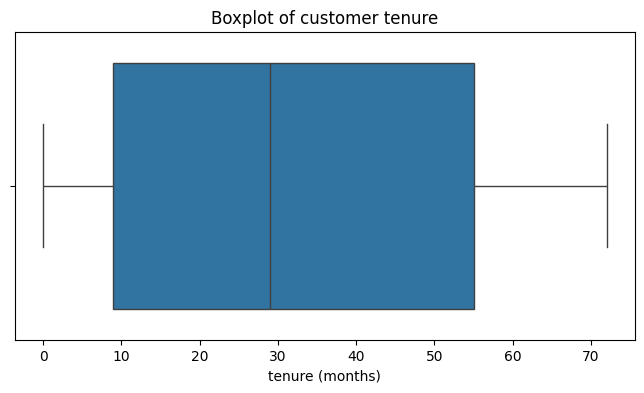

In [31]:
plt.figure(figsize = (8,4))
sns.boxplot(data = df, x = "tenure")
plt.title("Boxplot of customer tenure")
plt.xlabel("tenure (months)")



- Customer tenure ranges from 0 to 72 months, with a median of 29 months. The middle 50% of customers have tenure between 9 and 55 months. No outliers are identified using the 1.5 × IQR rule.

Text(0.5, 0, 'MonthlyCharges ($)')

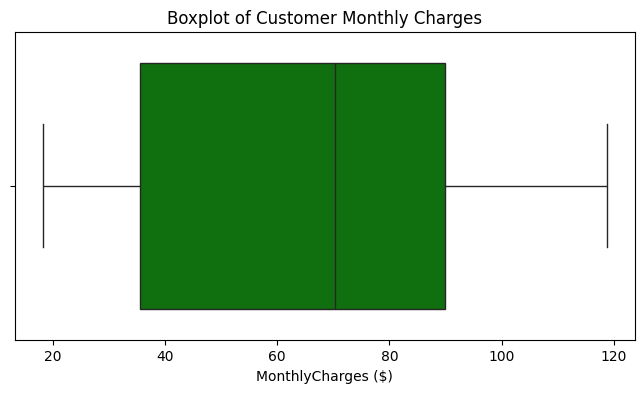

In [32]:
plt.figure(figsize = (8,4))
sns.boxplot(data = df, x="MonthlyCharges",color="green")
plt.title("Boxplot of Customer Monthly Charges")
plt.xlabel("MonthlyCharges ($)")

- Customer monthly charges ranges from $18 (approx) to $119 (approx).
- The middle 50% of customers pay between $35.50 and $89.85 per month.
- Half of the customers have monthly charges below or equal to $70.35(median), and the other half have charges above or equal to this value.
- No outlier identified using 1.5 x IQR method

Text(0.5, 0, 'TotalCharges ($)')

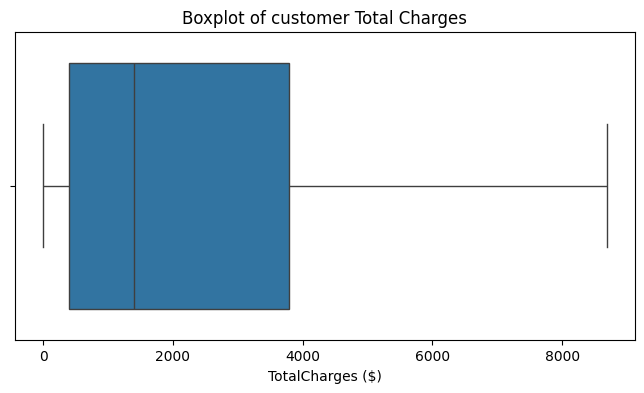

In [33]:
plt.figure(figsize=(8,4))
sns.boxplot(data = df, x = "TotalCharges")
plt.title("Boxplot of customer Total Charges")
plt.xlabel("TotalCharges ($)")

- TotalCharges ranges from $0 to $8,684.80, with a median of $1,394.55. The middle 50% of customers have accumulated charges between $398.55 and $3,786.60. No potential outliers were identified using the IQR method. The distribution is likely right-skewed because the mean ($2,279.73) is greater than the median.
 

Text(0, 0.5, 'Percentage of customer')

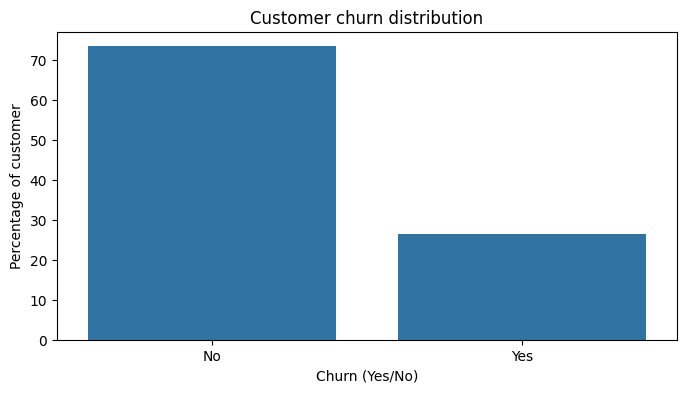

In [34]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "Churn", stat="percent")
plt.title("Customer churn distribution")
plt.xlabel("Churn (Yes/No)")
plt.ylabel("Percentage of customer")


- The dataset contains significantly more customers who stayed than customers who left.
- Approximately 73.5% of customers did not churn.
- Approximately 26.5% of customers churned. This indicates a considerable churn rate.
- The dataset is imbalanced because the number of customers in the two categories are significantly different.

Text(0, 0.5, 'Number of customers')

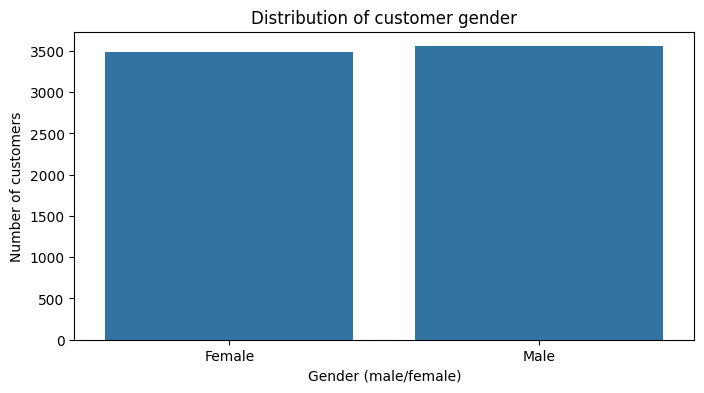

In [35]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "gender")
plt.title("Distribution of customer gender")
plt.xlabel("Gender (male/female)")
plt.ylabel("Number of customers")

- Male gender have slightly more customer as compare to female.
- There is no significant difference between male count and female count.
- The Distribution is approximately balanced in terms of gender of customer

Text(0.5, 0, 'SeniorCitizen (Yes = 1, No = 0)')

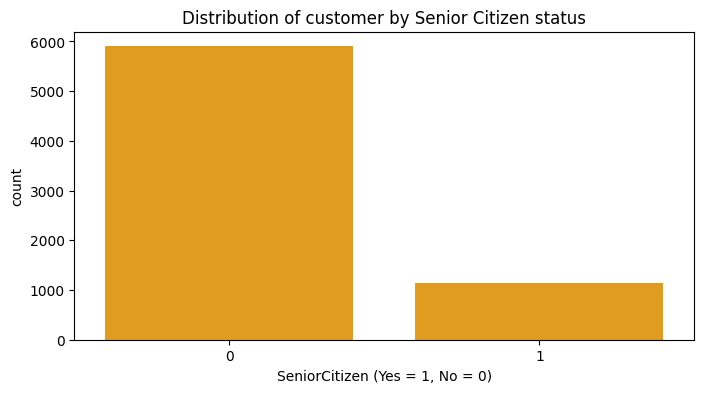

In [36]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "SeniorCitizen",color = "orange")
plt.title("Distribution of customer by Senior Citizen status")
plt.xlabel("SeniorCitizen (Yes = 1, No = 0)")

In [37]:
print("Frequency Distribution for SeniorCitizen")
print(df["SeniorCitizen"].value_counts())
print("*"*40)
print("Percentage distribution of SeniorCitizen")
print(df["SeniorCitizen"].value_counts(normalize=True)*100)

Frequency Distribution for SeniorCitizen
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
****************************************
Percentage distribution of SeniorCitizen
SeniorCitizen
0    83.785319
1    16.214681
Name: proportion, dtype: float64


- The Majority of customer belongs to Non SeniorCitizen category.
- Senior Citizen represent very small portion of total Customers.
- The SeniorCitizen column has imbalanced distribution.

Text(0, 0.5, 'Number of customers')

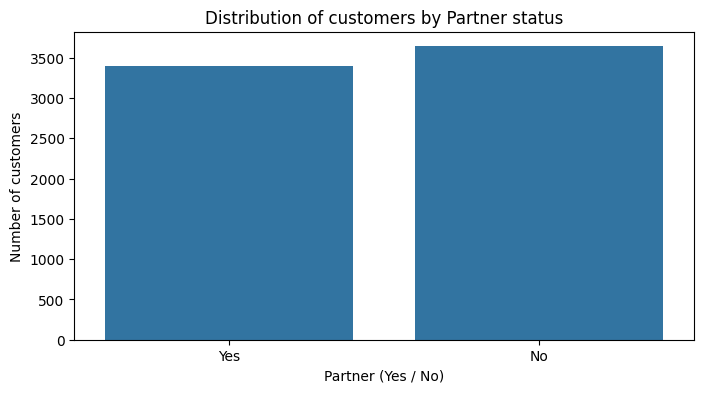

In [38]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "Partner")
plt.title("Distribution of customers by Partner status")
plt.xlabel("Partner (Yes / No)")
plt.ylabel("Number of customers")

In [39]:
print("Frequency distribution")
print(df["Partner"].value_counts())
print("*"*40)
print("Percentage Distribution")
print(df["Partner"].value_counts(normalize=True)*100)

Frequency distribution
Partner
No     3641
Yes    3402
Name: count, dtype: int64
****************************************
Percentage Distribution
Partner
No     51.69672
Yes    48.30328
Name: proportion, dtype: float64


- The number of customers without a partner is slightly higher than the number of customers with a partner.
- Both categories have a nearly equal distribution, with only a small difference of approximately 3.4 percentage points.
- The Partner column has a relatively balanced distribution. Approximately 51.70% of customers do not have a partner, while 48.30% have a partner.

Text(0, 0.5, 'Number of customers')

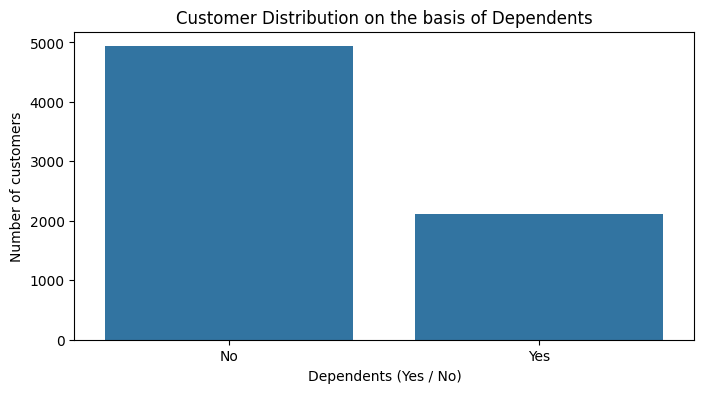

In [40]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "Dependents")
plt.title("Customer Distribution on the basis of Dependents")
plt.xlabel("Dependents (Yes / No)")
plt.ylabel("Number of customers")

In [41]:
print("Frequency Distribution")
print(df["Dependents"].value_counts())
print("*"*40)
print("Percentage Distribution")
print(df["Dependents"].value_counts(normalize=True)*100)

Frequency Distribution
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
****************************************
Percentage Distribution
Dependents
No     70.041176
Yes    29.958824
Name: proportion, dtype: float64


- Approximately 70% customers are independant.
- The Dependents column has an imbalanced distribution, with approximately 70.04% of customers having no dependents and 29.96% having dependents.

Text(0, 0.5, 'Number of customers')

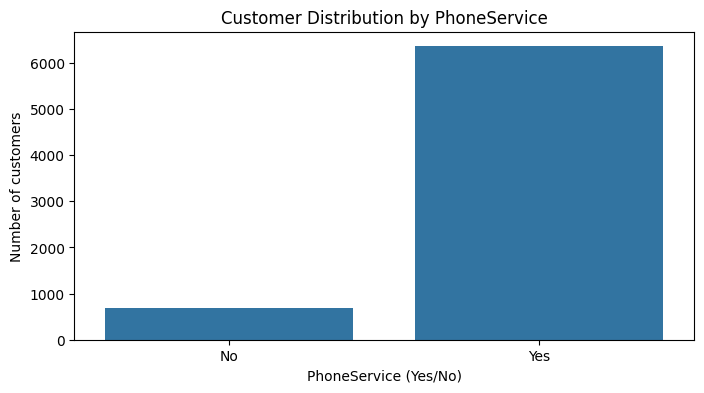

In [42]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x = "PhoneService")
plt.title("Customer Distribution by PhoneService")
plt.xlabel("PhoneService (Yes/No)")
plt.ylabel("Number of customers")

In [43]:
print("Frequency Distribution")
print(df["PhoneService"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["PhoneService"].value_counts(normalize=True)*100)

Frequency Distribution
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
******************************
Percentage Distribution
PhoneService
Yes    90.316626
No      9.683374
Name: proportion, dtype: float64


- The PhoneService column has a highly imbalanced distribution, with approximately 90.32% of customers using phone services and only 9.68% not using them.

Text(0, 0.5, 'Number of customers')

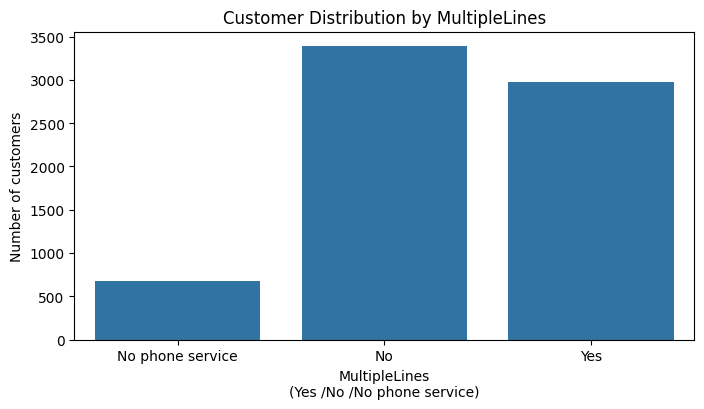

In [44]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="MultipleLines")
plt.title("Customer Distribution by MultipleLines")
plt.xlabel("MultipleLines\n(Yes /No /No phone service)")
plt.ylabel("Number of customers")

In [45]:
print("Frequency Distribution")
print(df["MultipleLines"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["MultipleLines"].value_counts(normalize=True)*100)

Frequency Distribution
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
******************************
Percentage Distribution
MultipleLines
No                  48.132898
Yes                 42.183729
No phone service     9.683374
Name: proportion, dtype: float64


- The MultipleLines column shows that 48.13% of customers do not have multiple lines, while 42.18% have multiple lines. The remaining 9.68% do not have phone service at all.

Text(0, 0.5, 'Number of Customers')

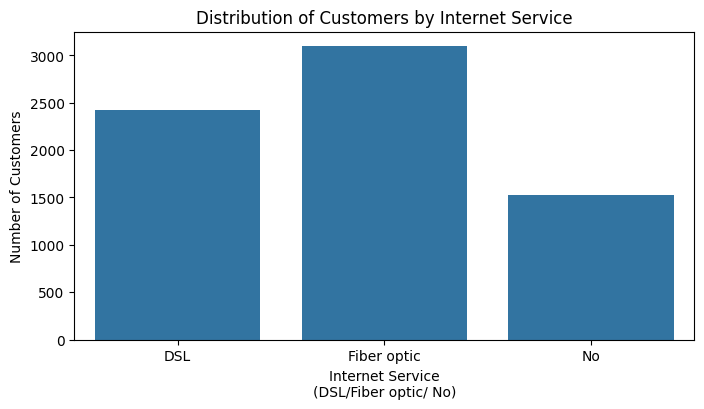

In [46]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="InternetService")
plt.title("Distribution of Customers by Internet Service")
plt.xlabel("Internet Service\n(DSL/Fiber optic/ No)")
plt.ylabel("Number of Customers")


In [47]:
print("Frequency Distribution")
print(df["InternetService"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["InternetService"].value_counts(normalize=True)*100)

Frequency Distribution
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
******************************
Percentage Distribution
InternetService
Fiber optic    43.958540
DSL            34.374556
No             21.666903
Name: proportion, dtype: float64


- Fiber optic is the most popular internet service, accounting for approximately 43.96% of customers, followed by DSL at 34.37%. Around 21.67% of customers do not use the company's internet services.

Text(0, 0.5, 'Number of Customers')

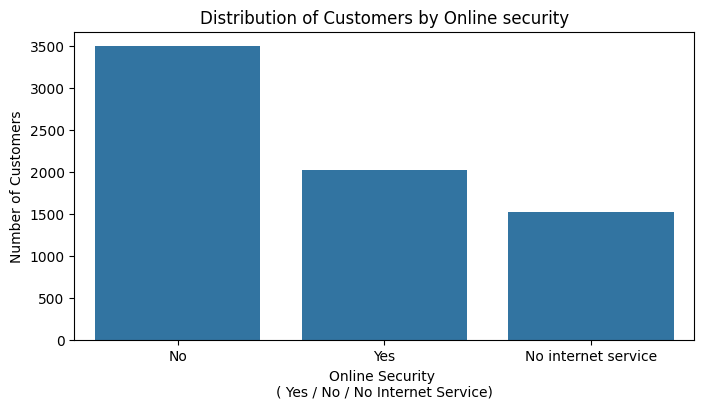

In [48]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="OnlineSecurity")
plt.title("Distribution of Customers by Online security")
plt.xlabel("Online Security \n( Yes / No / No Internet Service)")
plt.ylabel("Number of Customers")

In [49]:
print("Frequency Distribution")
print(df["OnlineSecurity"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["OnlineSecurity"].value_counts(normalize=True)*100)

Frequency Distribution
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
******************************
Percentage Distribution
OnlineSecurity
No                     49.666335
Yes                    28.666761
No internet service    21.666903
Name: proportion, dtype: float64


- The majority of customers either do not subscribe to OnlineSecurity or do not have an internet service. Only 28.67% of the total customers use the company's online security service.

Text(0, 0.5, 'Number of customers')

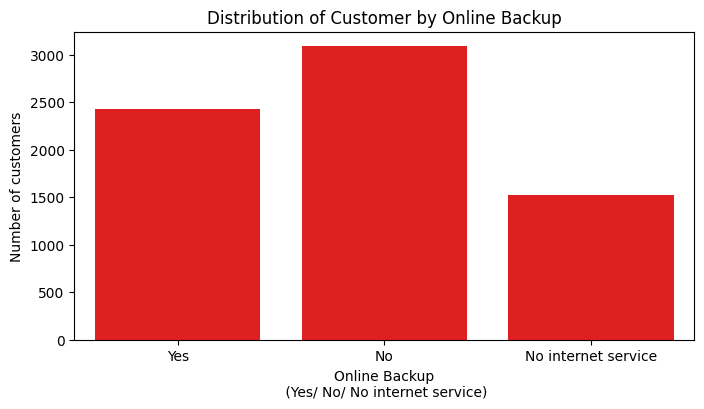

In [50]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="OnlineBackup", color="red")
plt.title("Distribution of Customer by Online Backup")
plt.xlabel("Online Backup\n (Yes/ No/ No internet service)")
plt.ylabel("Number of customers")

In [51]:
print("Frequency Distribution")
print(df["OnlineBackup"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["OnlineBackup"].value_counts(normalize=True)*100)

Frequency Distribution
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
******************************
Percentage Distribution
OnlineBackup
No                     43.844952
Yes                    34.488144
No internet service    21.666903
Name: proportion, dtype: float64


- The majority of customers (43.84%) do not subscribe to OnlineBackup, while 34.49% have subscribed to this service. The remaining 21.67% do not have an internet subscription.

Text(0, 0.5, 'Number of customers')

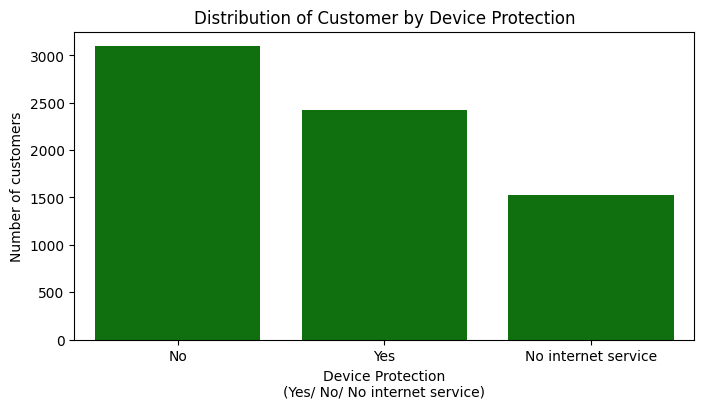

In [52]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="DeviceProtection", color="green")
plt.title("Distribution of Customer by Device Protection")
plt.xlabel("Device Protection\n(Yes/ No/ No internet service)")
plt.ylabel("Number of customers")

In [53]:
print("Frequency Distribution")
print(df["DeviceProtection"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["DeviceProtection"].value_counts(normalize=True)*100)

Frequency Distribution
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
******************************
Percentage Distribution
DeviceProtection
No                     43.944342
Yes                    34.388755
No internet service    21.666903
Name: proportion, dtype: float64


- The majority of customers (43.94%) do not subscribe to the DeviceProtection service, while 34.39% have subscribed. The remaining 21.67% do not have an internet subscription.


Text(0, 0.5, 'Number of customers')

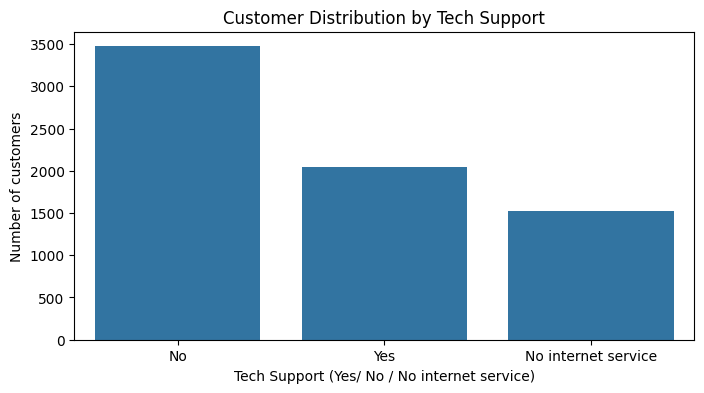

In [54]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "TechSupport")
plt.title("Customer Distribution by Tech Support")
plt.xlabel("Tech Support (Yes/ No / No internet service)")
plt.ylabel("Number of customers")

In [55]:
print("Frequency Distribution")
print(df["TechSupport"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["TechSupport"].value_counts(normalize=True)*100)

Frequency Distribution
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64
******************************
Percentage Distribution
TechSupport
No                     49.311373
Yes                    29.021724
No internet service    21.666903
Name: proportion, dtype: float64


- The majority of customers (49.31%) do not subscribe to the TechSupport service, while 34.39% have subscribed. The remaining 21.67% do not have an internet subscription.

Text(0, 0.5, 'Number of customers')

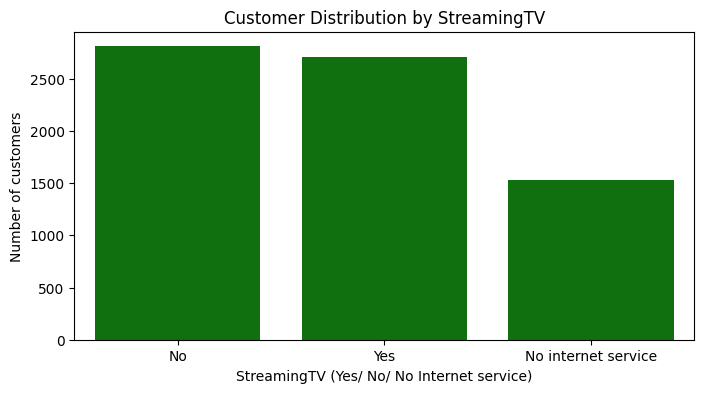

In [56]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "StreamingTV", color = "green")
plt.title("Customer Distribution by StreamingTV")
plt.xlabel("StreamingTV (Yes/ No/ No Internet service)")
plt.ylabel("Number of customers")

In [57]:
print("Frequency Distribution")
print(df["StreamingTV"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["StreamingTV"].value_counts(normalize=True)*100)

Frequency Distribution
StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64
******************************
Percentage Distribution
StreamingTV
No                     39.897771
Yes                    38.435326
No internet service    21.666903
Name: proportion, dtype: float64


- 38.43% of customers are using Streaming TV service and 39.89 do not subscribe for the same.
- There is no significant difference between customers who opt for the streamingTV service and those who don't

Text(0, 0.5, 'Number of customers')

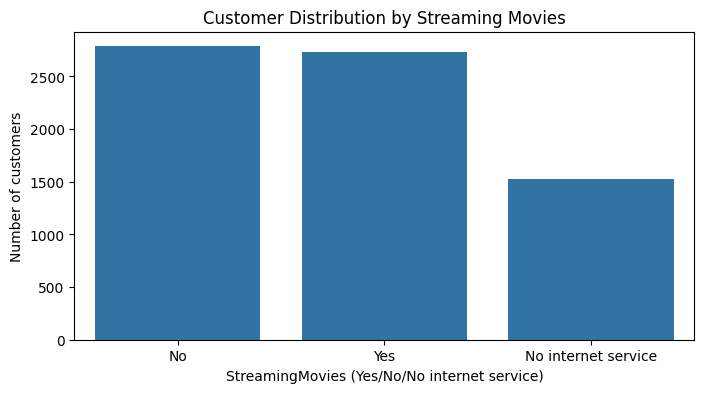

In [58]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "StreamingMovies")
plt.title("Customer Distribution by Streaming Movies")
plt.xlabel("StreamingMovies (Yes/No/No internet service)")
plt.ylabel("Number of customers")

In [59]:
print("Frequency Distribution")
print(df["StreamingMovies"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["StreamingMovies"].value_counts(normalize=True)*100)

Frequency Distribution
StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64
******************************
Percentage Distribution
StreamingMovies
No                     39.542808
Yes                    38.790288
No internet service    21.666903
Name: proportion, dtype: float64


- 38.79% of customers are using Streaming Movies service and 39.54% do not subscribe for the same.
- There is no significant difference between customers who opt for the streamingMovies service and those who don't.

Text(0, 0.5, 'Number of customers')

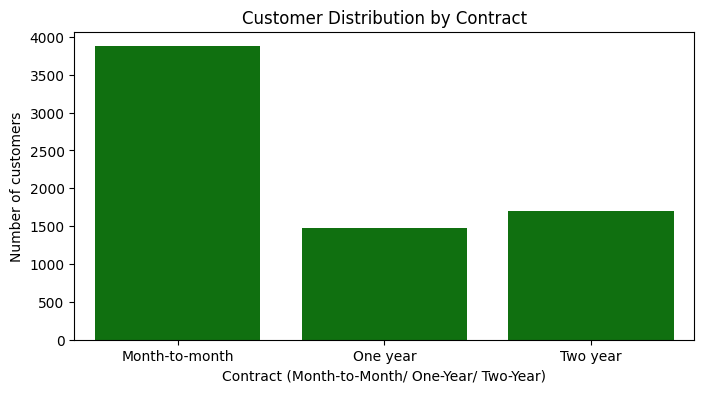

In [60]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "Contract", color = "green")
plt.title("Customer Distribution by Contract")
plt.xlabel("Contract (Month-to-Month/ One-Year/ Two-Year)")
plt.ylabel("Number of customers")

In [61]:
print("Frequency Distribution")
print(df["Contract"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["Contract"].value_counts(normalize=True)*100)

Frequency Distribution
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64
******************************
Percentage Distribution
Contract
Month-to-month    55.019168
Two year          24.066449
One year          20.914383
Name: proportion, dtype: float64


- Majority (55.02%) of customers prefer Month-to-month subscription.
- Long term services prefered by less customers.

Text(0, 0.5, 'Number of customers')

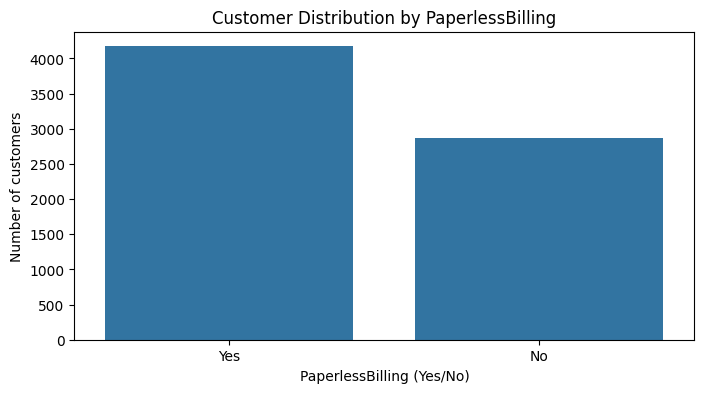

In [62]:
plt.figure(figsize=(8,4))
sns.countplot(data = df, x = "PaperlessBilling")
plt.title("Customer Distribution by PaperlessBilling")
plt.xlabel("PaperlessBilling (Yes/No)")
plt.ylabel("Number of customers")

In [63]:
print("Frequency Distribution")
print(df["PaperlessBilling"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["PaperlessBilling"].value_counts(normalize=True)*100)

Frequency Distribution
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64
******************************
Percentage Distribution
PaperlessBilling
Yes    59.221922
No     40.778078
Name: proportion, dtype: float64


- Aprrox 60% of customers prefer electronic billing.
- Paperlessbilling is prefered by 40.78% of customers

Text(0, 0.5, 'Number of customers')

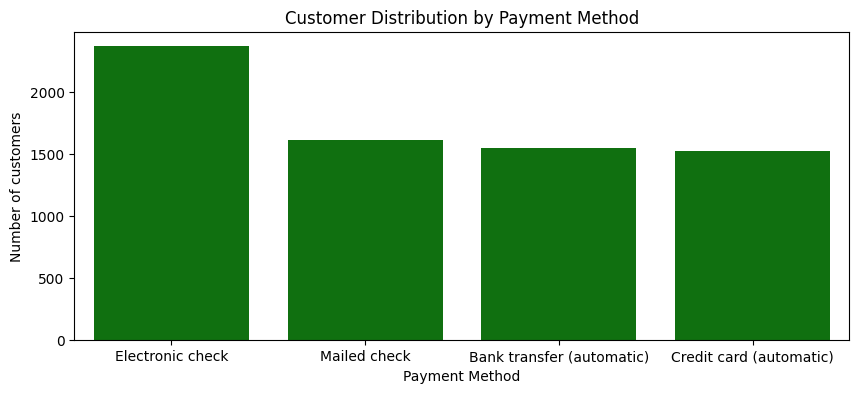

In [64]:
plt.figure(figsize=(10,4))
sns.countplot(data = df, x = "PaymentMethod", color = "green")
plt.title("Customer Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of customers")

In [65]:
print("Frequency Distribution")
print(df["PaymentMethod"].value_counts())
print("*"*30)
print("Percentage Distribution")
print(df["PaymentMethod"].value_counts(normalize=True)*100)

Frequency Distribution
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64
******************************
Percentage Distribution
PaymentMethod
Electronic check             33.579441
Mailed check                 22.887974
Bank transfer (automatic)    21.922476
Credit card (automatic)      21.610109
Name: proportion, dtype: float64


- Electronic check payment method is used by 33.58% of customers.
- Mailed check Bank transfer and Credit card is used by almost same proportion of customers (near 21.5% to 22.89%)

### Bivariate Analysis
- Target column is churn.
- We will analyse every column with Churn column

Text(0, 0.5, 'Number of customers')

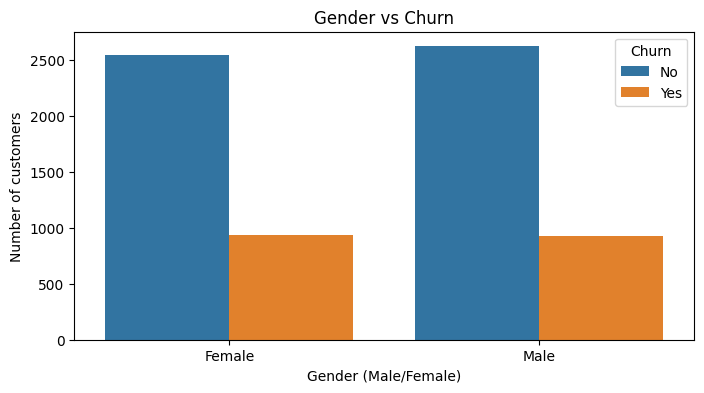

In [66]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="gender", hue="Churn")
plt.title("Gender vs Churn")
plt.xlabel("Gender (Male/Female)")
plt.ylabel("Number of customers")

In [67]:
pd.crosstab(df["gender"], df["Churn"], normalize='index')*100

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


- There is no significant difference between both the genders who has left the company.
- Similarly there is no significant difference between both the genders who stayed with the company

Text(0, 0.5, 'Number of customers')

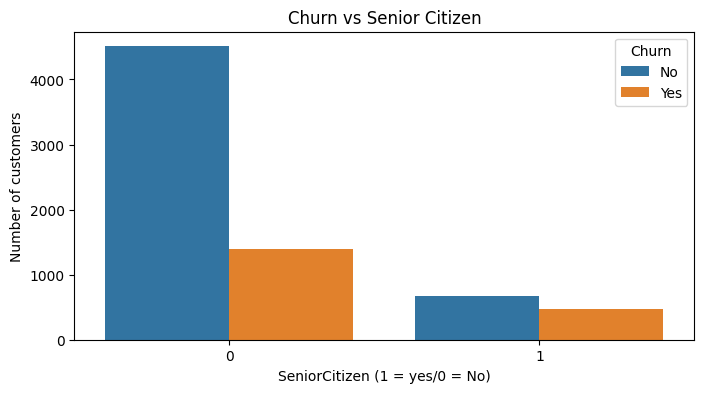

In [68]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="SeniorCitizen", hue="Churn")
plt.title("Churn vs Senior Citizen")
plt.xlabel("SeniorCitizen (1 = yes/0 = No)")
plt.ylabel("Number of customers")

In [69]:
pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize='index')*100


Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


- Senior citizens are more likely to leave the company's services compared to non-senior citizens. Approximately 41.68% of senior citizens churned, whereas only 23.61% of non-senior citizens churned.
- The company should investigate the reason that why sernior citizen are leaving the company with higher rate.

Text(0, 0.5, 'Number of customers')

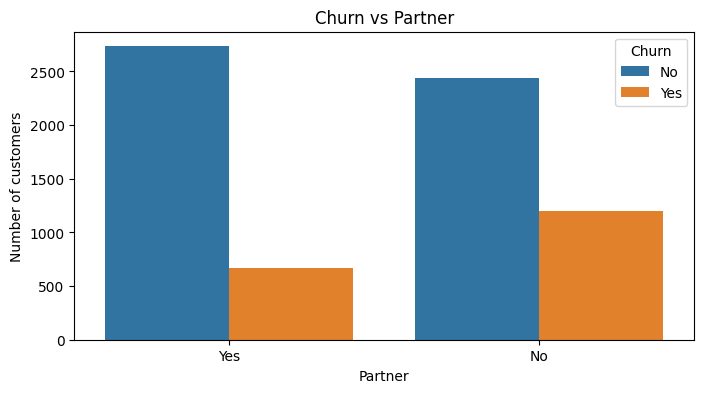

In [70]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="Partner", hue="Churn")
plt.title("Churn vs Partner")
plt.xlabel("Partner")
plt.ylabel("Number of customers")

In [71]:
pd.crosstab(df["Partner"], df["Churn"], normalize='index')*100


Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


- Customers without a partner have a considerably higher churn rate (32.96%) compared to customers with a partner (19.66%).
- The company could investigate the needs of customers without partners and consider targeted retention strategies, such as personalized offers, flexible plans, and improved customer engagement.
- However only the partner status cannot show the reason of churn further analysis is required.

Text(0, 0.5, 'Number of customers')

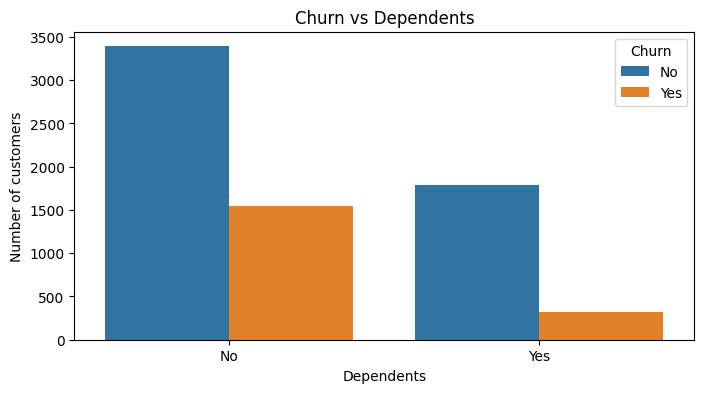

In [72]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="Dependents", hue="Churn")
plt.title("Churn vs Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of customers")

In [73]:
pd.crosstab(df["Dependents"],df["Churn"], normalize='index')*100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


- Customers without dependents have a considerably higher churn rate (31.28%) compared to customers with dependents (15.45%).
- The difference in churn rates is approximately 15.83 percentage.
- The company should focus on finding the reason that why churning rate is higher for those customers who do not have dependents.


Text(0, 0.5, 'Tenure (Months)')

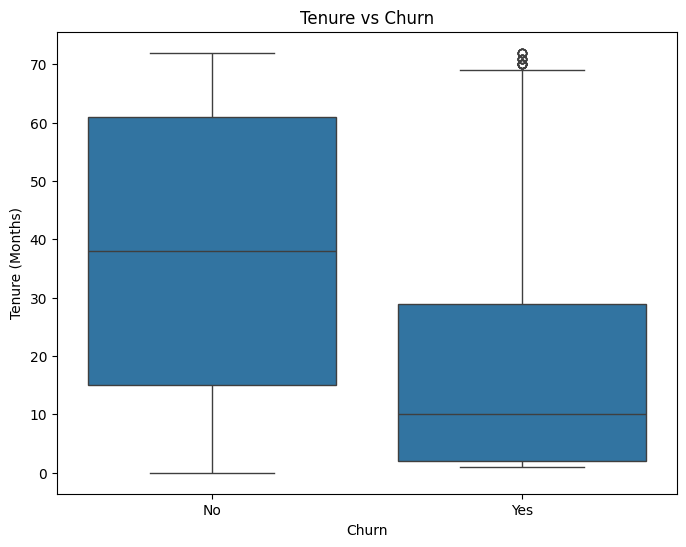

In [74]:
# tenure vs Churn --> Which customers are leaving the company--> are they newly joined ? 
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='Churn', y='tenure')
plt.title('Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')


In [75]:
df.groupby('Churn', as_index = False)['tenure'].describe()

,Churn,count,mean,std,min,25%,50%,75%,max
0,No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
1,Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


- Customers who did not churn have a considerably higher average tenure (37.57 months) compared to customers who churned (17.98 months).
- The median tenure of churned customers is only 10 months, whereas retained customers have a median tenure of 38 months.
- The large difference in median tenure suggests that customers who joined newly have higher churn rate as compare to those who have stayed with the company for the longer time.

In [76]:
# Now we will analyse churn with tenure in a slightly deeper way.
# Our target is to check exactly what range of  customers according to their tenure are leaving the company.
# We will divide the tenure in small groups.
bins =  [0,12,24,48,72]
label = labels = ['0-12 Months','13-24 Months','25-48 Months', '49-72 Months'] 

df["TenureGroup"] = pd.cut(df['tenure'], bins=bins, labels=label, include_lowest=True)
# The above command creates TenureGroup column in a dataset in which for every tenure one range is specified. Like if tenure is 1 then the range is "0-12 Months"

df[['tenure','Churn','TenureGroup']].head()

,tenure,Churn,TenureGroup
0,1,No,0-12 Months
1,34,No,25-48 Months
2,2,Yes,0-12 Months
3,45,No,25-48 Months
4,2,Yes,0-12 Months


In [77]:
tenure_analysis = df.groupby('TenureGroup',observed = True, as_index=False).agg(
    Total_Customers = ("Churn",'count'),
    Churned_Customers = ('Churn', lambda x: (x=='Yes').sum()),
    Retained_Customers = ('Churn',lambda x: (x=='No').sum()),
    Churn_Rate = ('Churn', lambda x :(x=='Yes').mean()*100) # Churn rate in each tenure groups
)
tenure_analysis


,TenureGroup,Total_Customers,Churned_Customers,Retained_Customers,Churn_Rate
0,0-12 Months,2186,1037,1149,47.438243
1,13-24 Months,1024,294,730,28.710938
2,25-48 Months,1594,325,1269,20.388959
3,49-72 Months,2239,213,2026,9.513176


Text(0, 0.5, 'Churn rate (%)')

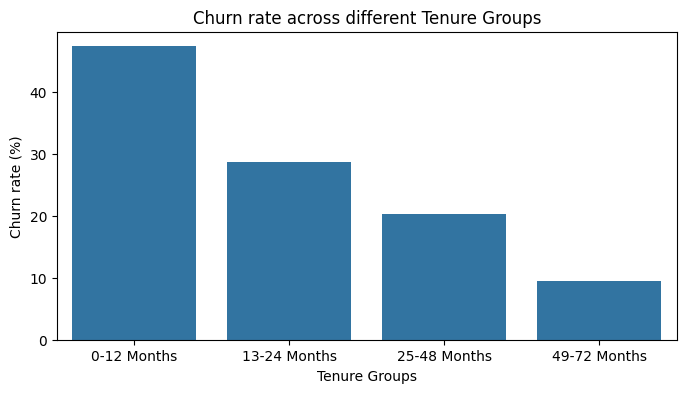

In [78]:
plt.figure(figsize=(8,4))
sns.barplot(data = tenure_analysis, x = 'TenureGroup', y = 'Churn_Rate')
plt.title("Churn rate across different Tenure Groups")
plt.xlabel("Tenure Groups")
plt.ylabel("Churn rate (%)")

- Almost half (47.44%) of customers in their first 12 months have churned.
- Customers in the first year have approximately five times the churn rate of long-term customers.
- The churn rate decreases from 47.44% to 9.51% as we move from the newest to the longest-tenured group.
- The company appears to have difficulty retaining newly acquired customers.
- Customer tenure has a strong relationship with churn. New customers are significantly more likely to leave the company compared to long-term customers. The highest churn occurs during the first 12 months, suggesting that the initial customer experience is a critical period for retention.

In [79]:
# Now we go more precisouly to analyse the churn rate of 0 to 12 month tenure by dividing it furthure
bins = [-1,3,6,9,12]
label = ["0-3 Months", "4-6 Months", "7-9 Months", "10-12 Months"]
df["EarlyTenureGroup"] = pd.cut(df["tenure"], bins = bins, labels = label)
df[["tenure", "TenureGroup", "EarlyTenureGroup"]].head()

,tenure,TenureGroup,EarlyTenureGroup
0,1,0-12 Months,0-3 Months
1,34,25-48 Months,NaN
2,2,0-12 Months,0-3 Months
3,45,25-48 Months,NaN
4,2,0-12 Months,0-3 Months


In [80]:
early_tenure_analysis = df.groupby("EarlyTenureGroup", observed = True, as_index=False).agg(
    Total_customers = ('Churn', 'count'),
    Churned_Customers = ('Churn', lambda x: (x=='Yes').sum()),
    Retained_Customers = ('Churn', lambda x: (x=='No').sum()),
    Churn_rate = ('Churn', lambda x: (x=='Yes').mean()*100)
)
early_tenure_analysis

,EarlyTenureGroup,Total_customers,Churned_Customers,Retained_Customers,Churn_rate
0,0-3 Months,1062,597,465,56.214689
1,4-6 Months,419,187,232,44.630072
2,7-9 Months,373,139,234,37.265416
3,10-12 Months,332,114,218,34.337349


Text(0, 0.5, 'Churn Rate (%)')

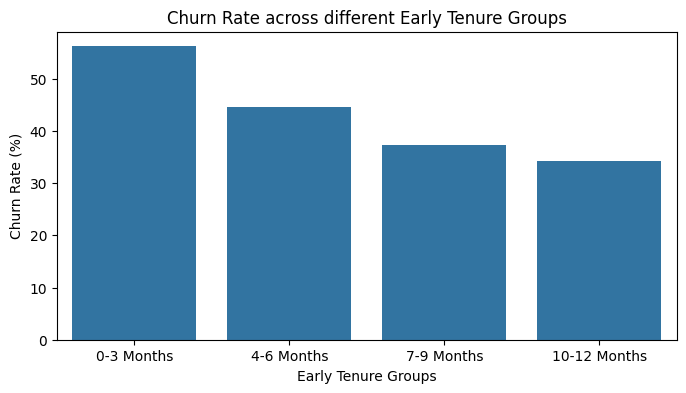

In [81]:
plt.figure(figsize=(8,4))
sns.barplot(data = early_tenure_analysis, x ='EarlyTenureGroup', y = 'Churn_rate')
plt.title("Churn Rate across different Early Tenure Groups")
plt.xlabel("Early Tenure Groups")
plt.ylabel("Churn Rate (%)")

- The early tenure analysis shows that customers are most likely to churn during their first three months after login, with a churn rate of 56.21%. The churn rate gradually decreases as customer tenure increases, reaching 34.34% during months 10–12. This indicates that customer retention is particularly challenging during the initial stages of the customer relationship. Therefore, telecom companies should prioritise onboarding, customer support, and early retention strategies.

- Contact customers during their first three months to identify problems.
- Offer suitable plans to customers who find their monthly charges too high.
- Monitor customer complaints and service quality during the initial months.

Text(0, 0.5, 'Number of customers')

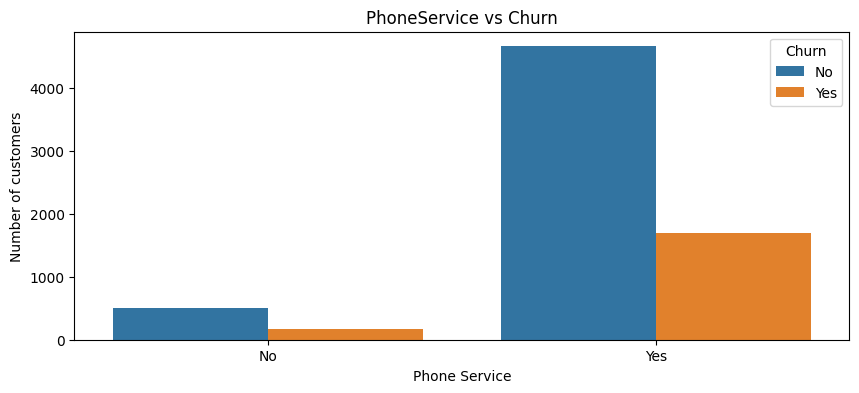

In [82]:
# PhoneService vs Churn
plt.figure(figsize=(10,4))
sns.countplot(data=df, x = 'PhoneService', hue= 'Churn')
plt.title("PhoneService vs Churn")
plt.xlabel("Phone Service")
plt.ylabel("Number of customers")


In [83]:
pd.crosstab(df["PhoneService"], df["Churn"], normalize='index')*100

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


- The Churn rate of Customers who are using Phone services is 26.71% and for those who are not using  is 24.9%.
- The difference between both is relatively small, suggesting that PhoneService usage alone may not be a significant indicator of customer churn.

Text(0, 0.5, 'Number of Customers')

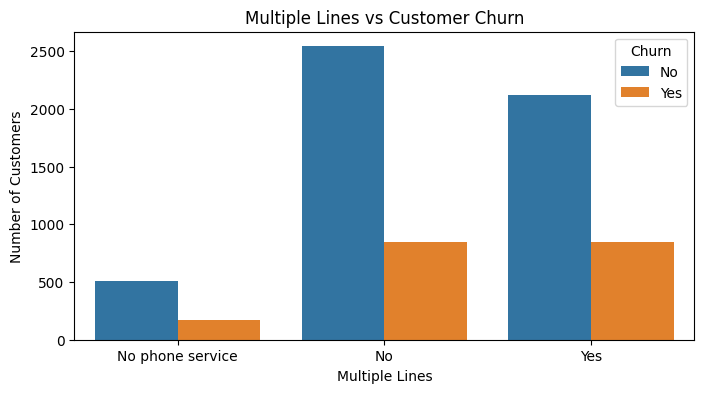

In [84]:
# MultipleLines vs Churn
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='MultipleLines', hue='Churn')

plt.title('Multiple Lines vs Customer Churn')
plt.xlabel('Multiple Lines')
plt.ylabel('Number of Customers')

In [85]:
pd.crosstab(df["MultipleLines"], df["Churn"], normalize='index')*100

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


- Customers with multiple phone lines have the highest churn rate (28.61%).
- Customers with a single phone line have a churn rate of 25.04%.
- Customers without phone service have a churn rate of 24.93%.
- This indicates a slightly higher churn rate among customers using multiple lines. However, the difference is relatively small, so MultipleLines alone may not be a strong predictor of customer churn.

Text(0, 0.5, 'Number of Customers')

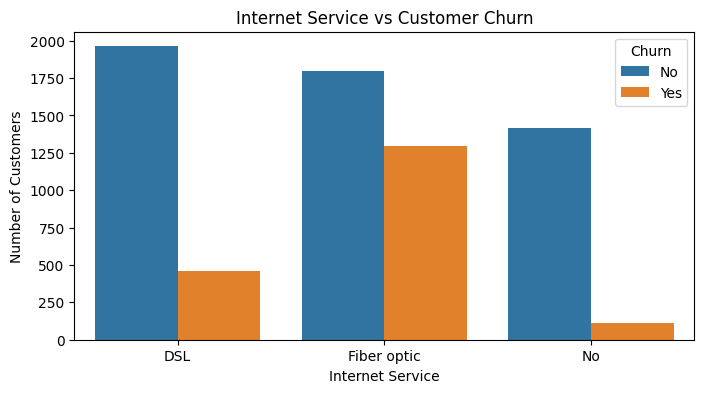

In [86]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.title('Internet Service vs Customer Churn')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')


In [87]:
pd.crosstab(df["InternetService"], df["Churn"], normalize='index')*100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


- The analysis shows that Fiber optic customers have the highest churn rate of 41.89%, followed by DSL customers at 18.96%
- The company should investigate factors such as pricing, service quality, and customer satisfaction among Fiber optic users to understand the possible reasons behind their higher churn.

Text(0, 0.5, 'Number of Customers')

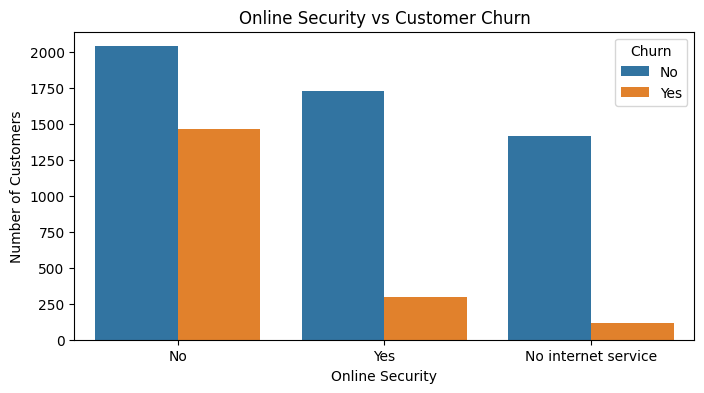

In [88]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='OnlineSecurity', hue='Churn')
plt.title('Online Security vs Customer Churn')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')


In [89]:
pd.crosstab(df["OnlineSecurity"],df["Churn"],normalize='index')*100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


- Customers without online security have highest churn rate of 41.77%
- Customers who has online security have lower churn rate.
- This suggests that OnlineSecurity subscription is associated with better customer retention.

Text(0, 0.5, 'Number of Customers')

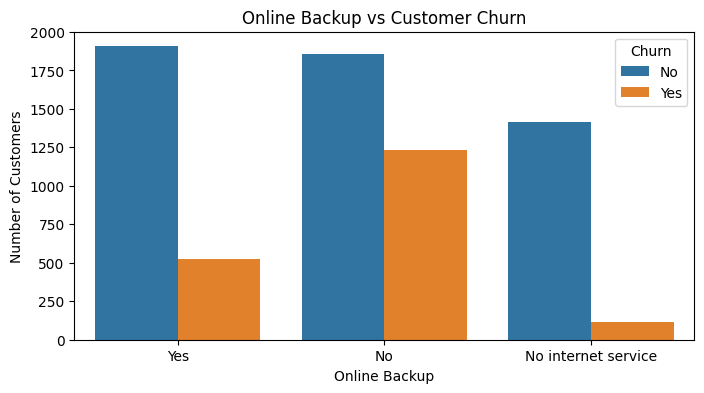

In [90]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='OnlineBackup', hue='Churn')
plt.title('Online Backup vs Customer Churn')
plt.xlabel('Online Backup')
plt.ylabel('Number of Customers')


In [91]:
pd.crosstab(df["OnlineBackup"],df["Churn"],normalize='index')*100

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


- Customers without OnlineBackup have the highest churn rate: 39.93%.
- This indicates that OnlineBackup subscription is associated with lower customer churn. Telecom companies could investigate whether offering additional services and suitable service bundles can improve customer retention.

Text(0, 0.5, 'Number of Customers')

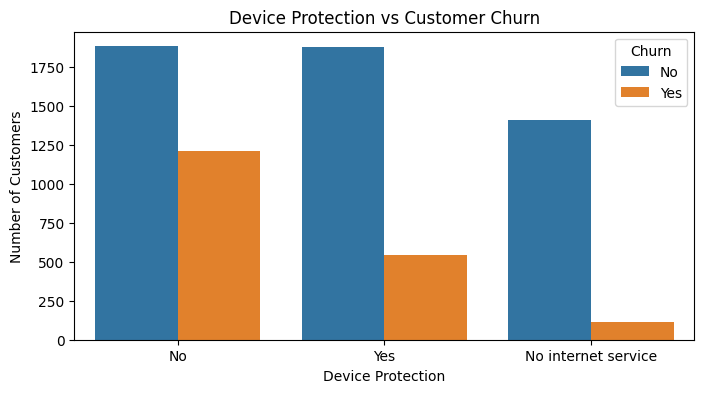

In [92]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='DeviceProtection', hue='Churn')
plt.title('Device Protection vs Customer Churn')
plt.xlabel('Device Protection')
plt.ylabel('Number of Customers')

In [93]:
pd.crosstab(df["DeviceProtection"],df["Churn"],normalize='index')*100

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


- Customers without DeviceProtection have the highest churn rate (39.13%).
- This indicates that DeviceProtection subscription is associated with better customer retention.
- Company should focus on better service of Device protection 

Text(0, 0.5, 'Number of Customers')

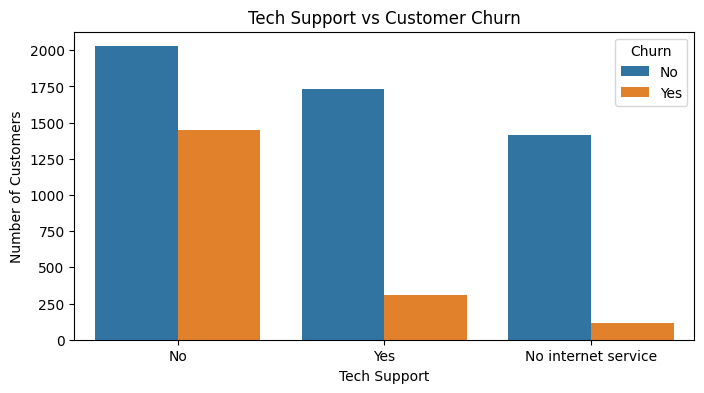

In [94]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='TechSupport', hue='Churn')

plt.title('Tech Support vs Customer Churn')
plt.xlabel('Tech Support')
plt.ylabel('Number of Customers')

In [95]:
pd.crosstab(df['TechSupport'], df['Churn'],  normalize='index') * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


- Customers who do not have Tech support have highest churn rate of 41.63%.
- Note one more thing, customers who are not using Internet service have highest retention rate.


Text(0, 0.5, 'Number of Customers')

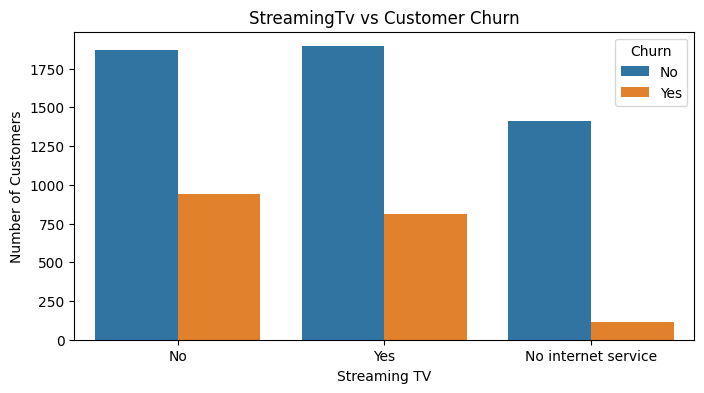

In [96]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x= 'StreamingTV', hue='Churn')
plt.title('StreamingTv vs Customer Churn')
plt.xlabel('Streaming TV')
plt.ylabel('Number of Customers')

In [97]:
pd.crosstab(df['StreamingTV'], df['Churn'],  normalize='index') * 100

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


- The analysis shows that customers who do not opt for Streaming TV have churn rate 33.5% and who opt for streaming Tv have churn rate 30.07%.
- The difference between the two internet-service customer groups is relatively small, suggesting that StreamingMovies subscription alone may not be a strong indicator of customer churn.

Text(0, 0.5, 'Number of Customers')

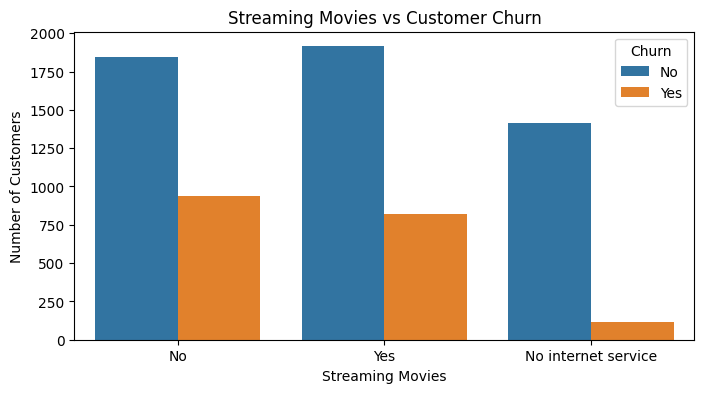

In [98]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x= 'StreamingMovies', hue='Churn')
plt.title('Streaming Movies vs Customer Churn')
plt.xlabel('Streaming Movies')
plt.ylabel('Number of Customers')

In [99]:
pd.crosstab(df['StreamingMovies'], df['Churn'],  normalize='index') * 100

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


- The difference between the two internet-service customer groups is relatively small, suggesting that StreamingMovies subscription alone may not be a strong indicator of customer churn.

Text(0, 0.5, 'Number of Customers')

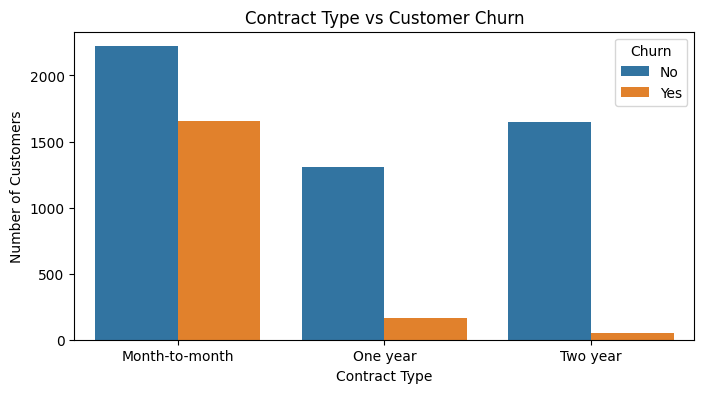

In [100]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Contract Type vs Customer Churn')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

In [101]:
pd.crosstab(df["Contract"],df["Churn"], normalize='index')*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


- Month-to-month contracts have the highest churn rate: 42.71%.
- The analysis shows that customers with month-to-month contracts have the highest churn rate of 42.71%, followed by one-year contracts at 11.27%. Customers with two-year contracts have the lowest churn rate of just 2.83%. This indicates a strong association between contract type and customer churn. Telecom companies could consider offering attractive incentives and long-term contract benefits to encourage customers to stay longer.

Text(0, 0.5, 'Number of Customers')

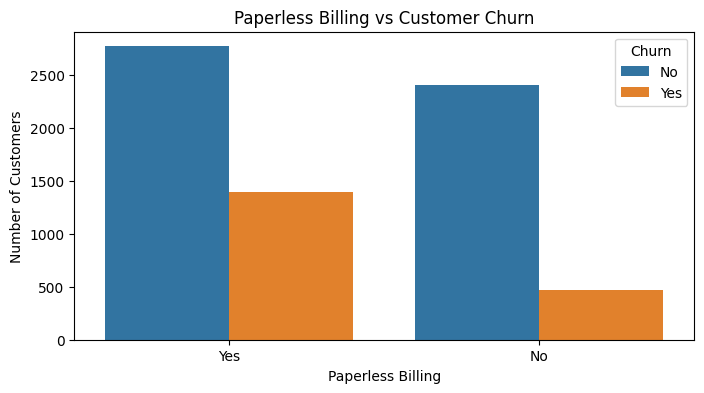

In [102]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='PaperlessBilling', hue='Churn')
plt.title('Paperless Billing vs Customer Churn')
plt.xlabel('Paperless Billing')
plt.ylabel('Number of Customers')

In [103]:
pd.crosstab(df["PaperlessBilling"], df["Churn"], normalize='index')*100

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


- The analysis shows that customers using paperless billing have a churn rate of 33.57%, compared with 16.33% among customers who do not use paperless billing.
- Telecom companies should investigate whether payment preferences, billing experience, or other customer characteristics contribute to this difference.

([0, 1, 2, 3],
 [Text(0, 0, 'Electronic check'),
  Text(1, 0, 'Mailed check'),
  Text(2, 0, 'Bank transfer (automatic)'),
  Text(3, 0, 'Credit card (automatic)')])

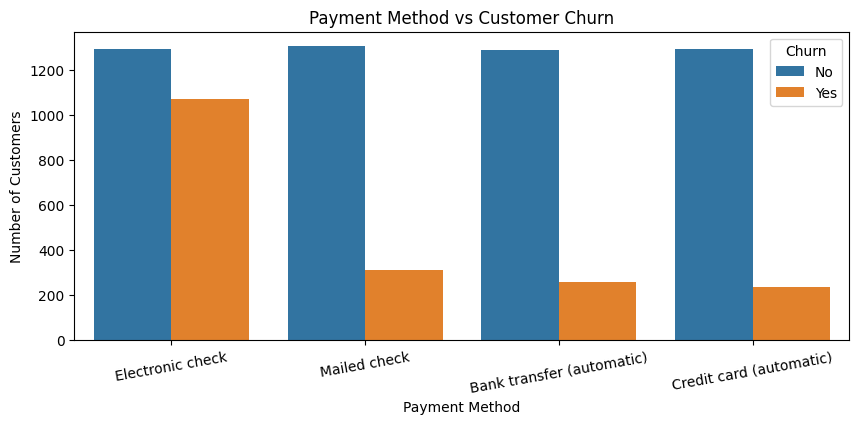

In [104]:
plt.figure(figsize=(10,4))
sns.countplot(data=df, x='PaymentMethod', hue='Churn')
plt.title('Payment Method vs Customer Churn')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=10)

In [105]:
pd.crosstab(df["PaymentMethod"],df["Churn"],normalize='index')*100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


- The analysis shows that customers using electronic checks have the highest churn rate of 45.29%, whereas customers using automatic credit card payments have the lowest churn rate of 15.24%. Customers using automatic bank transfers and mailed checks have churn rates of 16.71% and 19.11%, respectively. This indicates a strong association between payment method and customer churn.

##### Complete overview of Categorical bivariate analysis.
- The categorical bivariate analysis reveals that customer churn varies considerably across different customer characteristics and service categories. Electronic check users have the highest observed churn rate at 45.29%, followed by month-to-month contract customers at 42.71% and Fiber optic users at 41.89%. Customers without OnlineSecurity, OnlineBackup and DeviceProtection also show relatively high churn rates. In contrast, gender and PhoneService show comparatively small differences in churn rates. These findings suggest that contract type, payment method, internet service and additional service subscriptions deserve further investigation when developing customer retention strategies.

In [107]:
# Numerical bivariate analysis
df.groupby("Churn")['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


Text(0, 0.5, 'Monthly Charges')

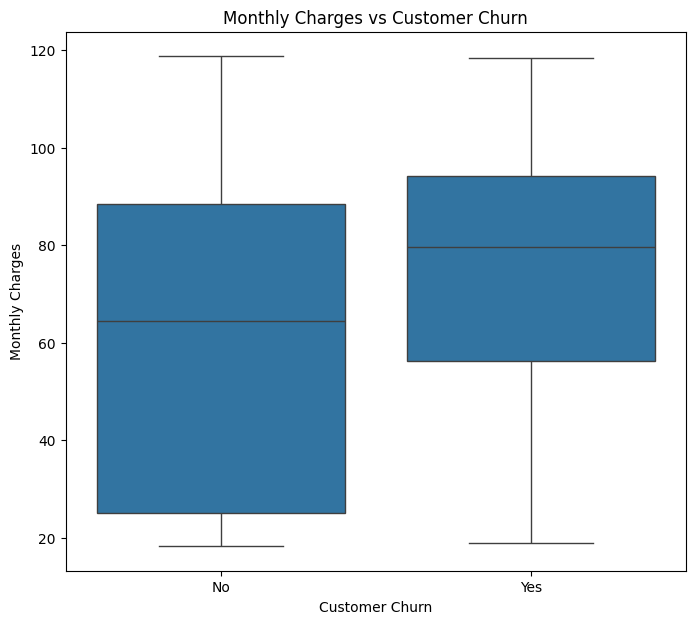

In [109]:
plt.figure(figsize=(8,7))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Charges')

- The analysis shows that churned customers have higher average monthly charges (74.44) compared with retained customers (61.27). The median monthly charge is also higher among churned customers (79.65) than retained customers (64.43). This suggests that customers paying higher monthly charges may be more likely to churn.